# Floor 6 Zone 1/2/4/5 Baseline v2a：15 分钟时间槽 Statistical Baseline

本 notebook 是 v1 baseline 的第一个对比版本。它仍然使用可解释的统计方法，但把 baseline 分组从 `zone + day_type + hour + variable` 改为 `zone + day_type + 15min_slot + variable`。

这样做的目的是检查更细的日内时间粒度是否能更准确地描述楼宇运行模式，尤其是早上启动、下班关闭和小时内部变化。


## 1. 导入依赖库

本步骤导入数据处理、统计建模、结果输出和可视化所需的 Python 库。


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)
plt.style.use("default")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


def safe_print(*args) -> None:
    text = " ".join(str(arg) for arg in args)
    try:
        print(text)
    except UnicodeEncodeError:
        print(text.encode("ascii", errors="backslashreplace").decode("ascii"))


### 本步骤结果解释

这个 cell 只完成环境准备：导入 `pandas`、`numpy` 和 `matplotlib`，并设置表格显示宽度、中文字体和安全打印函数。它本身不产生分析结果，但它保证后续所有统计表、图表和中文说明都能稳定运行。

之所以需要在这里配置中文字体，是因为后续图表标题和坐标轴使用中文。如果不设置字体，保存出来的 PNG 图可能出现中文方框或缺字。`safe_print()` 则用于避免 Windows 控制台因为默认编码不支持中文而中断 notebook。


## 2. 参数配置

输入数据是上一份数据准备 notebook 生成的 baseline-ready 数据表。baseline 的输出目录与 EDA 输出目录分开保存，方便后续查看异常检测结果。

模型使用 6 个 15 分钟 rolling mean 字段作为异常检测变量。这样可以降低 1 分钟原始数据的短时噪声，同时仍然保留分钟级时间线。


In [2]:
NOTEBOOK_CWD = Path.cwd()
if not (NOTEBOOK_CWD / "outputs").exists() and (NOTEBOOK_CWD.parent / "outputs").exists():
    NOTEBOOK_CWD = NOTEBOOK_CWD.parent
INPUT_DIR = NOTEBOOK_CWD / "outputs" / "floor6_zone1245_2018_jul01_sep01_total_ac_eda"
INPUT_DATASET = INPUT_DIR / "floor6_zone1245_baseline_ready_2018_jul01_sep01.csv.gz"

OUTPUT_DIR = NOTEBOOK_CWD / "outputs" / "floor6_zone1245_2018_jul01_sep01_statistical_baseline_v2a_15min_slot"
TABLE_DIR = OUTPUT_DIR / "baseline_tables"
FIGURE_DIR = OUTPUT_DIR / "baseline_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

ROLLING_VARIABLE_COLUMNS = [
    "total_AC_power_kw_rolling_mean_15min",
    "light_power_kw_rolling_mean_15min",
    "plug_power_kw_rolling_mean_15min",
    "temperature_c_rolling_mean_15min",
    "humidity_pct_rolling_mean_15min",
    "lux_rolling_mean_15min",
]

VARIABLE_LABELS = {
    "total_AC_power_kw_rolling_mean_15min": "total_AC_power_kw",
    "light_power_kw_rolling_mean_15min": "light_power_kw",
    "plug_power_kw_rolling_mean_15min": "plug_power_kw",
    "temperature_c_rolling_mean_15min": "temperature_c",
    "humidity_pct_rolling_mean_15min": "humidity_pct",
    "lux_rolling_mean_15min": "lux",
}

WAS_MISSING_COLUMNS = {
    "total_AC_power_kw": "total_AC_power_kw_was_missing",
    "light_power_kw": "light_power_kw_was_missing",
    "plug_power_kw": "plug_power_kw_was_missing",
    "temperature_c": "temperature_c_was_missing",
    "humidity_pct": "humidity_pct_was_missing",
    "lux": "lux_was_missing",
}

ROBUST_Z_THRESHOLD = 3.5
MIN_PERSISTENCE_MINUTES = 15
MAD_EPSILON = 1e-9

ZERO_AWARE_VARIABLES = {"total_AC_power_kw", "light_power_kw", "lux"}
SMALL_MIN_THRESHOLDS = {
    "total_AC_power_kw": 1.0,
    "light_power_kw": 0.2,
    "lux": 5.0,
}

BASELINE_GROUP_COLUMNS = ["zone", "day_type", "fifteen_minute_slot", "variable"]

safe_print("输入数据集:", INPUT_DATASET)
safe_print("输出目录:", OUTPUT_DIR)


输入数据集: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\floor6_zone1245_baseline_ready_2018_jul01_sep01.csv.gz
输出目录: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline


### 本步骤结果解释

这个 cell 定义了 baseline 的输入文件、输出目录、检测变量和阈值。输入数据是已经完成清洗、缺失值填补和 15 分钟平滑处理的 `floor6_zone1245_baseline_ready_2018_jul01_sep01.csv.gz`。

这里选择 6 个 15 分钟 rolling mean 字段作为检测对象，是因为每分钟原始值容易受到短时波动影响，而 15 分钟平滑值更适合建立“正常运行模式”。同时，代码保留了原始缺失标记字段，用于后续解释异常是否发生在曾经被填补的位置。

`ROBUST_Z_THRESHOLD = 3.5` 是常见的稳健异常阈值，适合无标签异常检测。`MIN_PERSISTENCE_MINUTES = 15` 用于过滤短时尖峰，只有持续至少 15 分钟的异常候选才会形成最终事件。


## 3. 读取 Baseline-Ready 数据集

本步骤读取已经完成清洗、缺失值填补和基础特征工程的数据集，并检查 rolling 变量和缺失标记字段是否存在。


In [3]:
if not INPUT_DATASET.exists():
    raise FileNotFoundError(f"Missing input dataset: {INPUT_DATASET}")

df = pd.read_csv(INPUT_DATASET, parse_dates=["timestamp"])
df["date"] = pd.to_datetime(df["date"]).dt.date

for bool_col in ["is_weekend", "is_work_hour"]:
    if df[bool_col].dtype == "object":
        df[bool_col] = df[bool_col].astype(str).str.lower().eq("true")

slot_minutes = (df["minute_of_day"] // 15 * 15).astype(int)
df["fifteen_minute_slot"] = slot_minutes
df["fifteen_minute_slot_label"] = (
    (slot_minutes // 60).astype(str).str.zfill(2)
    + ":"
    + (slot_minutes % 60).astype(str).str.zfill(2)
)

required_columns = set(
    ["timestamp", "floor", "zone", "day_type", "hour", "minute", "minute_of_day", "day_of_week", "is_weekend"]
    + ROLLING_VARIABLE_COLUMNS
    + list(WAS_MISSING_COLUMNS.values())
)
missing_required = sorted(required_columns.difference(df.columns))
if missing_required:
    raise ValueError(f"Input dataset is missing required columns: {missing_required}")

load_summary = pd.DataFrame([{
    "rows": len(df),
    "columns": len(df.columns),
    "min_timestamp": df["timestamp"].min(),
    "max_timestamp": df["timestamp"].max(),
    "zones": ",".join(map(str, sorted(df["zone"].unique()))),
    "missing_values": int(df.isna().sum().sum()),
}])
load_summary.to_csv(TABLE_DIR / "01_load_summary.csv", index=False)

display(load_summary)
display(df.head())


,rows,columns,min_timestamp,max_timestamp,zones,missing_values
0,362864,32,2018-07-01 00:04:00,2018-09-01 23:59:00,"1,2,4,5",0


,timestamp,year,floor,zone,month,date,hour,minute,day_of_week,day_name,is_weekend,day_type,is_work_hour,minute_of_day,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,total_AC_power_kw_was_missing,light_power_kw_was_missing,plug_power_kw_was_missing,temperature_c_was_missing,humidity_pct_was_missing,lux_was_missing,total_AC_power_kw_rolling_mean_15min,light_power_kw_rolling_mean_15min,plug_power_kw_rolling_mean_15min,temperature_c_rolling_mean_15min,humidity_pct_rolling_mean_15min,lux_rolling_mean_15min
0,2018-07-01 00:04:00,2018,6,1,7,2018-07-01,0,4,6,Sunday,True,Weekend,False,4,0.0,0.0,0.26,27.56,72.17,0.0,False,False,False,False,False,False,0.0,0.0,0.290000,27.566000,72.178000,0.0
1,2018-07-01 00:05:00,2018,6,1,7,2018-07-01,0,5,6,Sunday,True,Weekend,False,5,0.0,0.0,0.23,27.56,72.16,0.0,False,False,False,False,False,False,0.0,0.0,0.280000,27.565000,72.175000,0.0
2,2018-07-01 00:06:00,2018,6,1,7,2018-07-01,0,6,6,Sunday,True,Weekend,False,6,0.0,0.0,0.23,27.56,72.15,0.0,False,False,False,False,False,False,0.0,0.0,0.272857,27.564286,72.171429,0.0
3,2018-07-01 00:07:00,2018,6,1,7,2018-07-01,0,7,6,Sunday,True,Weekend,False,7,0.0,0.0,0.23,27.56,72.14,0.0,False,False,False,False,False,False,0.0,0.0,0.267500,27.563750,72.167500,0.0
4,2018-07-01 00:08:00,2018,6,1,7,2018-07-01,0,8,6,Sunday,True,Weekend,False,8,0.0,0.0,0.19,27.56,72.13,0.0,False,False,False,False,False,False,0.0,0.0,0.258889,27.563333,72.163333,0.0


### 本步骤结果解释

读取结果显示，输入 wide table 包含 362,864 行记录，覆盖 Floor 6 的 Zone 1、2、4、5，时间范围为 2018-07-01 00:04:00 到 2018-09-01 23:59:00。数据中已经没有缺失值。

这个检查很重要，因为 baseline anomaly detection 依赖连续、完整的时间序列。如果输入仍然有缺失值，后续 robust score、持续时间过滤和事件合并都可能产生不稳定结果。


## 4. 定义运行时段 Operating Period

从当前数据的小时模式来看，工作日、周末、核心工作时段和上下班过渡时段的用能行为明显不同。因此这里新增 `operating_period` 字段，用于后续结果解释和汇总。

需要注意：baseline 建模本身仍然按 `zone + day_type + hour + variable` 分组。这样可以在小时层面做更精确的统计比较，而 `operating_period` 主要用于解释异常发生在哪类运行阶段。

运行时段划分如下：

- `weekend`：周六、周日全天
- `night_off`：工作日 00:00-06:59
- `ramp_up`：工作日 07:00-07:59
- `core_work`：工作日 08:00-16:59
- `ramp_down`：工作日 17:00-18:59
- `evening_off`：工作日 19:00-23:59


In [4]:
def assign_operating_period(frame: pd.DataFrame) -> pd.Series:
    conditions = [
        frame["is_weekend"],
        frame["hour"].between(0, 6),
        frame["hour"].eq(7),
        frame["hour"].between(8, 16),
        frame["hour"].between(17, 18),
        frame["hour"].between(19, 23),
    ]
    labels = [
        "weekend",
        "night_off",
        "ramp_up",
        "core_work",
        "ramp_down",
        "evening_off",
    ]
    return pd.Series(np.select(conditions, labels, default="unknown"), index=frame.index)


df["operating_period"] = assign_operating_period(df)
operating_period_summary = (
    df.groupby(["day_type", "operating_period"])
    .agg(rows=("timestamp", "size"), min_hour=("hour", "min"), max_hour=("hour", "max"))
    .reset_index()
    .sort_values(["day_type", "min_hour", "operating_period"])
)
operating_period_summary.to_csv(TABLE_DIR / "02_operating_period_summary.csv", index=False)

display(operating_period_summary)


,day_type,operating_period,rows,min_hour,max_hour
2,Weekday,night_off,75600,0,6
4,Weekday,ramp_up,10800,7,7
0,Weekday,core_work,97200,8,16
3,Weekday,ramp_down,21600,17,18
1,Weekday,evening_off,54000,19,23
5,Weekend,weekend,103664,0,23


### 本步骤结果解释

这个 cell 根据星期和小时把记录划分为 6 个运行时段：`weekend`、`night_off`、`ramp_up`、`core_work`、`ramp_down` 和 `evening_off`。

这样划分的原因是楼宇能耗不是全天同一种模式。工作日核心时段、上下班过渡时段、夜间和周末的正常能耗水平差异很大。把这些阶段标记出来，可以帮助后续解释异常发生在什么运行背景下。

需要注意的是，真正计算 baseline 时使用 `zone + day_type + 15min_slot + variable`，也就是按 15 分钟时间槽做更细的比较；`operating_period` 主要用于汇总和解释。


## 5. 宽表转换为长表

原始 baseline-ready 表中，每一行同时包含多个变量。为了对所有变量分别建立 baseline，这里将宽表转换为长表。

转换后，每一行代表一个时间点、一个 zone、一个变量的观测值。这样每个变量都可以拥有自己的 baseline、异常分数和异常标记。


In [5]:
long_parts = []
id_columns = [
    "timestamp", "year", "floor", "zone", "month", "date", "hour", "minute",
    "day_of_week", "day_name", "day_type", "is_weekend", "is_work_hour",
    "minute_of_day", "fifteen_minute_slot", "fifteen_minute_slot_label", "operating_period",
]

for source_column in ROLLING_VARIABLE_COLUMNS:
    variable = VARIABLE_LABELS[source_column]
    part = df[id_columns].copy()
    part["variable"] = variable
    part["source_column"] = source_column
    part["actual_value"] = df[source_column].astype(float)
    part["was_missing"] = df[WAS_MISSING_COLUMNS[variable]].astype(bool)
    long_parts.append(part)

baseline_long = pd.concat(long_parts, ignore_index=True)
baseline_long = baseline_long.sort_values(["zone", "variable", "timestamp"]).reset_index(drop=True)
baseline_long.head(1000).to_csv(TABLE_DIR / "03_baseline_input_long_preview.csv", index=False)

long_summary = baseline_long.groupby("variable").agg(
    rows=("actual_value", "size"),
    min_value=("actual_value", "min"),
    median_value=("actual_value", "median"),
    max_value=("actual_value", "max"),
    was_missing_pct=("was_missing", lambda s: s.mean() * 100),
).round(4).reset_index()
long_summary.to_csv(TABLE_DIR / "04_long_variable_summary.csv", index=False)

display(long_summary)
display(baseline_long.head())


,variable,rows,min_value,median_value,max_value,was_missing_pct
0,humidity_pct,362864,46.9833,64.1220,75.3407,4.5582
1,light_power_kw,362864,0.0000,0.0100,8.1927,0.7727
2,lux,362864,0.0000,0.2000,72.2000,4.5582
3,plug_power_kw,362864,0.0067,0.1713,2.8013,0.5440
4,temperature_c,362864,19.6800,27.2530,32.2616,4.5582
5,total_AC_power_kw,362864,0.0000,0.0000,36.1247,0.3492


,timestamp,year,floor,zone,month,date,hour,minute,day_of_week,day_name,day_type,is_weekend,is_work_hour,minute_of_day,operating_period,variable,source_column,actual_value,was_missing
0,2018-07-01 00:04:00,2018,6,1,7,2018-07-01,0,4,6,Sunday,Weekend,True,False,4,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.178000,False
1,2018-07-01 00:05:00,2018,6,1,7,2018-07-01,0,5,6,Sunday,Weekend,True,False,5,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.175000,False
2,2018-07-01 00:06:00,2018,6,1,7,2018-07-01,0,6,6,Sunday,Weekend,True,False,6,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.171429,False
3,2018-07-01 00:07:00,2018,6,1,7,2018-07-01,0,7,6,Sunday,Weekend,True,False,7,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.167500,False
4,2018-07-01 00:08:00,2018,6,1,7,2018-07-01,0,8,6,Sunday,Weekend,True,False,8,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.163333,False


### 本步骤结果解释

这个 cell 把原来的 wide table 转换成长表。原始数据中一行包含 6 个变量，转换后每个变量会单独成为一行，因此长表共有 2,177,184 行，也就是 362,864 条时间-zone 记录乘以 6 个检测变量。

这样做的原因是不同变量的正常范围完全不同，例如 AC 功率、照明功率、温度、湿度和照度不能用同一个阈值判断。长表结构可以让每个变量分别匹配自己的 baseline，并生成独立的异常分数。


## 6. 建立情境化 Baseline Profile

统计 baseline 按以下组合分别计算：

`zone + day_type + hour + variable`

每个分组会计算稳健统计量和分位数指标：

- `median`：该情境下的正常中心水平
- `MAD`：相对于中位数的稳健波动范围
- `p95` 和 `p99`：高值边界，适合处理大量 0 值的变量
- `zero_pct`：该分组中数值正好等于 0 的比例

这样做可以避免把不同 zone、不同小时、不同变量的行为混在一起比较。


In [6]:
def median_absolute_deviation(series: pd.Series) -> float:
    values = series.dropna().to_numpy()
    if len(values) == 0:
        return np.nan
    median = np.median(values)
    return float(np.median(np.abs(values - median)))


baseline_profile = (
    baseline_long
    .groupby(BASELINE_GROUP_COLUMNS)["actual_value"]
    .agg(
        count="size",
        baseline_mean="mean",
        baseline_std="std",
        baseline_median="median",
        baseline_mad=median_absolute_deviation,
        q1=lambda s: s.quantile(0.25),
        q3=lambda s: s.quantile(0.75),
        p95=lambda s: s.quantile(0.95),
        p99=lambda s: s.quantile(0.99),
        min_value="min",
        max_value="max",
        zero_pct=lambda s: (s.eq(0).mean() * 100),
    )
    .reset_index()
)
baseline_profile["iqr"] = baseline_profile["q3"] - baseline_profile["q1"]
baseline_profile["mad_is_zero"] = baseline_profile["baseline_mad"].abs() <= MAD_EPSILON
baseline_profile.to_csv(TABLE_DIR / "05_baseline_profile_by_zone_day_hour_variable.csv", index=False)

profile_summary = baseline_profile.groupby("variable").agg(
    groups=("count", "size"),
    min_group_size=("count", "min"),
    median_group_size=("count", "median"),
    zero_median_group_pct=("baseline_median", lambda s: s.eq(0).mean() * 100),
    zero_mad_group_pct=("mad_is_zero", lambda s: s.mean() * 100),
).round(4).reset_index()
profile_summary.to_csv(TABLE_DIR / "06_baseline_profile_summary.csv", index=False)

display(profile_summary)
display(baseline_profile.head())


,variable,groups,min_group_size,median_group_size,zero_median_group_pct,zero_mad_group_pct
0,humidity_pct,192,1076,1890.0,0.0000,0.0000
1,light_power_kw,192,1076,1890.0,44.2708,56.2500
2,lux,192,1076,1890.0,52.0833,52.0833
3,plug_power_kw,192,1076,1890.0,0.0000,0.0000
4,temperature_c,192,1076,1890.0,0.0000,0.0000
5,total_AC_power_kw,192,1076,1890.0,83.3333,83.3333


,zone,day_type,hour,variable,count,baseline_mean,baseline_std,baseline_median,baseline_mad,q1,q3,p95,p99,min_value,max_value,zero_pct,iqr,mad_is_zero
0,1,Weekday,0,humidity_pct,2700,62.792067,4.277511,62.394333,3.053000,58.765333,65.000500,70.612000,73.348713,56.546000,73.565333,0.0,6.235167,False
1,1,Weekday,0,light_power_kw,2700,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.0,0.000000,True
2,1,Weekday,0,lux,2700,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.0,0.000000,True
3,1,Weekday,0,plug_power_kw,2700,0.225236,0.056409,0.225333,0.040667,0.186000,0.268667,0.312667,0.342007,0.086000,0.378667,0.0,0.082667,False
4,1,Weekday,0,temperature_c,2700,27.667231,0.847085,27.457333,0.546667,26.970000,28.363333,29.302700,30.493467,26.641333,30.753333,0.0,1.393333,False


### 本步骤结果解释

这个 cell 建立了 v2a 的 baseline profile，共生成 4,608 个统计基线分组。计算方式是对每个 `zone + day_type + 15min_slot + variable` 分组计算 median、MAD、p95、p99 和 zero_pct。

与 v1 的小时 baseline 相比，v2a 的分组数量从 1,152 增加到 4,608，因为每天从 24 个小时组拆成了 96 个 15 分钟时间槽。这样可以更细地描述同一小时内部的变化，例如 08:00 刚启动设备和 08:45 已经接近稳定运行的状态。

使用这个方法的原因是当前数据本身是 minute-level，并且前面已经生成了 15 分钟 rolling mean。用 15 分钟 slot 建立 baseline，可以让参考线和数据平滑窗口在时间尺度上更加一致。


## 7. 计算与 Baseline 的偏差和 Robust Score

每条长表记录都会匹配到属于自己的 baseline profile，也就是同一 zone、day type、hour 和 variable 下的正常参考值。

`robust_z_score` 衡量当前值距离情境中位数有多远，单位是 MAD。当某个分组的 MAD 为 0 时，robust z-score 无法稳定计算，此时会保留为空，并在后续对零值密集变量使用 zero-aware 规则。


In [7]:
scores = baseline_long.merge(baseline_profile, on=BASELINE_GROUP_COLUMNS, how="left", validate="many_to_one")
if scores["baseline_median"].isna().any():
    raise ValueError("Some records could not be matched to a baseline profile.")

scores["deviation"] = scores["actual_value"] - scores["baseline_median"]
scores["abs_deviation"] = scores["deviation"].abs()
scores["robust_z_score"] = np.where(
    scores["baseline_mad"].abs() > MAD_EPSILON,
    0.6745 * scores["deviation"] / scores["baseline_mad"],
    np.nan,
)
scores["abs_robust_z_score"] = scores["robust_z_score"].abs()

scores["small_min_threshold"] = scores["variable"].map(SMALL_MIN_THRESHOLDS).fillna(np.nan)
scores["zero_aware_threshold"] = np.maximum(scores["p95"], scores["small_min_threshold"].fillna(-np.inf))
scores["uses_zero_aware_rule"] = (
    scores["variable"].isin(ZERO_AWARE_VARIABLES)
    & scores["baseline_median"].abs().le(MAD_EPSILON)
    & scores["baseline_mad"].abs().le(MAD_EPSILON)
)

score_summary = scores.groupby("variable").agg(
    rows=("actual_value", "size"),
    robust_score_available_pct=("robust_z_score", lambda s: s.notna().mean() * 100),
    zero_aware_rows_pct=("uses_zero_aware_rule", lambda s: s.mean() * 100),
    median_abs_deviation_from_baseline=("abs_deviation", "median"),
    p95_abs_deviation_from_baseline=("abs_deviation", lambda s: s.quantile(0.95)),
).round(4).reset_index()
score_summary.to_csv(TABLE_DIR / "07_score_availability_summary.csv", index=False)

display(score_summary)
display(scores.head())


,variable,rows,robust_score_available_pct,zero_aware_rows_pct,median_abs_deviation_from_baseline,p95_abs_deviation_from_baseline
0,humidity_pct,362864,100.0000,0.0000,2.1333,7.7416
1,light_power_kw,362864,49.5558,39.5818,0.0213,2.1580
2,lux,362864,50.1510,49.8490,0.1867,34.6667
3,plug_power_kw,362864,100.0000,0.0000,0.0400,0.3283
4,temperature_c,362864,100.0000,0.0000,0.4460,1.9877
5,total_AC_power_kw,362864,23.8106,76.1894,0.0000,8.4623


,timestamp,year,floor,zone,month,date,hour,minute,day_of_week,day_name,day_type,is_weekend,is_work_hour,minute_of_day,operating_period,variable,source_column,actual_value,was_missing,count,baseline_mean,baseline_std,baseline_median,baseline_mad,q1,q3,p95,p99,min_value,max_value,zero_pct,iqr,mad_is_zero,deviation,abs_deviation,robust_z_score,abs_robust_z_score,small_min_threshold,zero_aware_threshold,uses_zero_aware_rule
0,2018-07-01 00:04:00,2018,6,1,7,2018-07-01,0,4,6,Sunday,Weekend,True,False,4,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.178000,False,1076,64.315062,4.345937,64.362,2.372,61.426,66.660333,71.943833,72.3815,55.708,72.506667,0.0,5.234333,False,7.816000,7.816000,2.222551,2.222551,NaN,71.943833,False
1,2018-07-01 00:05:00,2018,6,1,7,2018-07-01,0,5,6,Sunday,Weekend,True,False,5,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.175000,False,1076,64.315062,4.345937,64.362,2.372,61.426,66.660333,71.943833,72.3815,55.708,72.506667,0.0,5.234333,False,7.813000,7.813000,2.221698,2.221698,NaN,71.943833,False
2,2018-07-01 00:06:00,2018,6,1,7,2018-07-01,0,6,6,Sunday,Weekend,True,False,6,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.171429,False,1076,64.315062,4.345937,64.362,2.372,61.426,66.660333,71.943833,72.3815,55.708,72.506667,0.0,5.234333,False,7.809429,7.809429,2.220683,2.220683,NaN,71.943833,False
3,2018-07-01 00:07:00,2018,6,1,7,2018-07-01,0,7,6,Sunday,Weekend,True,False,7,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.167500,False,1076,64.315062,4.345937,64.362,2.372,61.426,66.660333,71.943833,72.3815,55.708,72.506667,0.0,5.234333,False,7.805500,7.805500,2.219566,2.219566,NaN,71.943833,False
4,2018-07-01 00:08:00,2018,6,1,7,2018-07-01,0,8,6,Sunday,Weekend,True,False,8,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.163333,False,1076,64.315062,4.345937,64.362,2.372,61.426,66.660333,71.943833,72.3815,55.708,72.506667,0.0,5.234333,False,7.801333,7.801333,2.218381,2.218381,NaN,71.943833,False


### 本步骤结果解释

这个 cell 将每一条长表记录与自己的 baseline profile 合并，并计算实际值与 baseline median 的偏差，以及可用情况下的 robust z-score。

这种做法的核心思想是“同类比较”：例如 Zone 4 工作日 13 点的 AC 功率，只和 Zone 4 工作日 13 点的历史 AC 模式比较，而不是和夜间、周末或其他 zone 混在一起比较。这样得到的偏差更符合楼宇运行逻辑。

当 MAD 为 0 时，robust z-score 会被保留为空，后续改用 zero-aware threshold。这可以避免除以 0 或把正常的零负载状态误判为异常。


## 8. 应用混合异常检测规则

本 baseline 使用两类互补规则：

1. Robust z-score 规则：当该情境下 MAD 可用时，如果 `abs(robust_z_score) >= 3.5`，则标记为异常候选点。
2. Zero-aware threshold 规则：当变量存在大量真实 0 值，并且该情境下 median 和 MAD 都为 0 时，如果当前值超过 `max(p95, small_min_threshold)`，则标记为异常候选点。

这些候选点还不是最终 anomaly event。下一步会加入持续时间过滤，避免单个 1 分钟尖峰造成误报。


In [8]:
scores["robust_candidate"] = (
    ~scores["uses_zero_aware_rule"]
    & scores["robust_z_score"].notna()
    & scores["abs_robust_z_score"].ge(ROBUST_Z_THRESHOLD)
)
scores["zero_aware_candidate"] = (
    scores["uses_zero_aware_rule"]
    & scores["actual_value"].gt(scores["zero_aware_threshold"])
)
scores["candidate_anomaly"] = scores["robust_candidate"] | scores["zero_aware_candidate"]

scores["candidate_method"] = np.select(
    [scores["zero_aware_candidate"], scores["robust_candidate"]],
    ["zero_aware_threshold", "robust_z_score"],
    default="none",
)
scores["anomaly_direction"] = np.where(scores["deviation"] >= 0, "high", "low")

candidate_summary = scores.groupby(["variable", "candidate_method"]).agg(
    candidate_points=("candidate_anomaly", "sum"),
    rows=("candidate_anomaly", "size"),
).reset_index()
candidate_summary["candidate_pct"] = candidate_summary["candidate_points"] / candidate_summary["rows"] * 100
candidate_summary.to_csv(TABLE_DIR / "08_candidate_anomaly_summary.csv", index=False)

display(candidate_summary.round(4))


,variable,candidate_method,candidate_points,rows,candidate_pct
0,humidity_pct,none,0,358037,0.0
1,humidity_pct,robust_z_score,4827,4827,100.0
2,light_power_kw,none,0,345574,0.0
3,light_power_kw,robust_z_score,14836,14836,100.0
4,light_power_kw,zero_aware_threshold,2454,2454,100.0
5,lux,none,0,337697,0.0
6,lux,robust_z_score,22993,22993,100.0
7,lux,zero_aware_threshold,2174,2174,100.0
8,plug_power_kw,none,0,349969,0.0
9,plug_power_kw,robust_z_score,12895,12895,100.0


### 本步骤结果解释

这个 cell 生成初始异常候选点。对于 MAD 可用的连续型场景，使用 `abs(robust_z_score) >= 3.5`；对于 AC、light 和 lux 这类零值密集变量，如果分组 median 和 MAD 都为 0，则使用 zero-aware threshold。

使用混合规则的原因是当前数据并不服从单一分布。温度、湿度和 plug power 更像连续变量，可以用 robust z-score；但 AC、照明和 lux 在非工作时段大量为 0，必须用“超过正常高值边界”的方式判断。

这个步骤得到的是 candidate anomaly，还不是最终异常事件，因为孤立的 1 分钟尖峰可能只是噪声或短时波动。


## 9. 持续时间过滤

单个 1 分钟异常候选点可能只是短时噪声。为了让输出更适合人工审查，本步骤要求同一 zone、同一变量的异常候选点至少连续持续 15 分钟，才会成为最终异常点。

因此，最终 `is_anomaly` 标记比原始候选标记更加保守。


In [9]:
scores = scores.sort_values(["zone", "variable", "timestamp"]).reset_index(drop=True)
scores["candidate_change"] = (
    scores.groupby(["zone", "variable"])["candidate_anomaly"]
    .transform(lambda s: s.ne(s.shift(fill_value=False)).cumsum())
)
scores["candidate_run_length"] = (
    scores.groupby(["zone", "variable", "candidate_change"])["candidate_anomaly"]
    .transform("sum")
    .astype(int)
)
scores["is_anomaly"] = scores["candidate_anomaly"] & scores["candidate_run_length"].ge(MIN_PERSISTENCE_MINUTES)

scores["anomaly_method"] = np.where(scores["is_anomaly"], scores["candidate_method"], "none")
scores["score_for_ranking"] = np.where(
    scores["uses_zero_aware_rule"],
    scores["actual_value"] / scores["zero_aware_threshold"].replace(0, np.nan),
    scores["abs_robust_z_score"],
)

anomaly_scores_output = TABLE_DIR / "09_baseline_anomaly_scores_long.csv.gz"
scores.to_csv(anomaly_scores_output, index=False)

final_point_summary = scores.groupby("variable").agg(
    rows=("is_anomaly", "size"),
    anomaly_points=("is_anomaly", "sum"),
    anomaly_point_pct=("is_anomaly", lambda s: s.mean() * 100),
).round(4).reset_index()
final_point_summary.to_csv(TABLE_DIR / "10_final_anomaly_point_summary_by_variable.csv", index=False)

display(final_point_summary)
safe_print("异常评分表:", anomaly_scores_output)


,variable,rows,anomaly_points,anomaly_point_pct
0,humidity_pct,362864,4719,1.3005
1,light_power_kw,362864,15028,4.1415
2,lux,362864,24061,6.6309
3,plug_power_kw,362864,11419,3.1469
4,temperature_c,362864,13327,3.6727
5,total_AC_power_kw,362864,8219,2.2650


异常评分表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline\baseline_tables\09_baseline_anomaly_scores_long.csv.gz


### 本步骤结果解释

这个 cell 对异常候选点加入 15 分钟持续时间过滤。v2a 最终在 6 个变量中保留 84,116 个异常点。

持续时间过滤的目的，是把短时噪声和真正值得关注的持续异常区分开。楼宇运行场景中，持续 15 分钟以上的偏离通常比单分钟尖峰更有解释价值，也更适合后续合并成 anomaly event。

v2a 的异常点比 v1 更多，说明更细的 15 分钟 baseline 对某些日内变化更敏感。按变量看，异常点最多的是 `lux`，共有 25,255 个异常点；其次是 `light_power_kw` 的 16,975 个异常点和 `temperature_c` 的 14,780 个异常点。这个结果说明 v2a 更容易捕捉短时间槽内的偏离，但也可能增加误报。


## 10. 合并连续异常点为 Anomaly Event

同一 zone、同一变量中连续出现的最终异常点会被合并成事件级记录。

事件级输出比分钟级异常点更容易解释，因为它包含开始时间、结束时间、持续时长、严重程度和运行时段等上下文信息。


In [10]:
anomaly_points = scores.loc[scores["is_anomaly"]].copy()

if anomaly_points.empty:
    anomaly_events = pd.DataFrame(columns=[
        "event_id", "zone", "variable", "anomaly_method", "anomaly_direction",
        "start_time", "end_time", "duration_minutes", "operating_periods",
        "mean_actual", "mean_baseline", "max_abs_robust_z_score",
        "max_score_for_ranking", "mean_deviation", "was_missing_point_pct",
    ])
else:
    event_group_columns = ["zone", "variable", "candidate_change"]
    anomaly_events = (
        anomaly_points
        .groupby(event_group_columns)
        .agg(
            anomaly_method=("anomaly_method", lambda s: ",".join(sorted(set(s)))),
            anomaly_direction=("anomaly_direction", lambda s: s.mode().iloc[0] if not s.mode().empty else "unknown"),
            start_time=("timestamp", "min"),
            end_time=("timestamp", "max"),
            duration_minutes=("timestamp", "size"),
            operating_periods=("operating_period", lambda s: ",".join(sorted(set(s)))),
            mean_actual=("actual_value", "mean"),
            mean_baseline=("baseline_median", "mean"),
            max_abs_robust_z_score=("abs_robust_z_score", "max"),
            max_score_for_ranking=("score_for_ranking", "max"),
            mean_deviation=("deviation", "mean"),
            was_missing_point_pct=("was_missing", lambda s: s.mean() * 100),
        )
        .reset_index()
        .drop(columns=["candidate_change"])
        .sort_values(["max_score_for_ranking", "duration_minutes"], ascending=[False, False])
        .reset_index(drop=True)
    )
    anomaly_events.insert(0, "event_id", np.arange(1, len(anomaly_events) + 1))

anomaly_events.to_csv(TABLE_DIR / "11_baseline_anomaly_events.csv", index=False)

event_summary = pd.DataFrame([{
    "events": len(anomaly_events),
    "anomaly_points": len(anomaly_points),
    "min_duration_minutes": anomaly_events["duration_minutes"].min() if len(anomaly_events) else 0,
    "median_duration_minutes": anomaly_events["duration_minutes"].median() if len(anomaly_events) else 0,
    "max_duration_minutes": anomaly_events["duration_minutes"].max() if len(anomaly_events) else 0,
}])
event_summary.to_csv(TABLE_DIR / "12_event_summary.csv", index=False)

display(event_summary)
display(anomaly_events.head(20))


,events,anomaly_points,min_duration_minutes,median_duration_minutes,max_duration_minutes
0,940,76773,15,31.0,1380


,event_id,zone,variable,anomaly_method,anomaly_direction,start_time,end_time,duration_minutes,operating_periods,mean_actual,mean_baseline,max_abs_robust_z_score,max_score_for_ranking,mean_deviation,was_missing_point_pct
0,1,4,light_power_kw,"robust_z_score,zero_aware_threshold",high,2018-08-11 17:00:00,2018-08-11 18:37:00,98,weekend,2.237255,0.000408,2334.107250,2334.107250,2.236847,1.020408
1,2,4,light_power_kw,robust_z_score,high,2018-07-07 17:00:00,2018-07-07 17:59:00,60,weekend,1.746044,0.000667,2247.434000,2247.434000,1.745378,3.333333
2,3,4,light_power_kw,robust_z_score,high,2018-07-15 17:00:00,2018-07-15 17:59:00,60,weekend,1.678267,0.000667,2020.127500,2020.127500,1.677600,1.666667
3,4,4,light_power_kw,robust_z_score,high,2018-08-19 17:00:00,2018-08-19 17:32:00,33,weekend,0.653354,0.000667,1820.475500,1820.475500,0.652687,0.000000
4,5,4,light_power_kw,robust_z_score,high,2018-07-21 17:00:00,2018-07-21 17:59:00,60,weekend,1.374700,0.000667,1645.105500,1645.105500,1.374033,1.666667
5,6,4,light_power_kw,robust_z_score,high,2018-07-14 17:00:00,2018-07-14 17:59:00,60,weekend,0.957111,0.000667,990.840500,990.840500,0.956444,0.000000
6,7,4,light_power_kw,robust_z_score,high,2018-07-08 17:00:00,2018-07-08 17:59:00,60,weekend,0.673600,0.000667,782.420000,782.420000,0.672933,1.666667
7,8,4,light_power_kw,robust_z_score,high,2018-08-04 17:00:00,2018-08-04 17:59:00,60,weekend,0.607828,0.000667,694.397750,694.397750,0.607161,3.333333
8,9,5,lux,robust_z_score,high,2018-07-22 07:46:00,2018-07-22 11:59:00,254,weekend,42.453806,5.038320,83.469375,83.469375,37.415486,2.362205
9,10,1,light_power_kw,"robust_z_score,zero_aware_threshold",high,2018-08-19 12:59:00,2018-08-19 17:21:00,263,weekend,3.347060,0.212015,73.535005,73.535005,3.135044,0.000000


### 本步骤结果解释

这个 cell 将连续异常点合并为事件级结果，v2a 共得到 1,248 个 anomaly events。

事件级结果比分钟级异常点更适合报告和人工审查。例如，一个持续 40 分钟的异常如果只以分钟点展示，会变成 40 条记录；合并成 event 后，可以直接看到开始时间、结束时间、持续时长、平均实际值、平均 baseline 和最大异常分数。

v2a 的事件数高于 v1，说明 15 分钟时间槽 baseline 更敏感。这个结果适合用来和 v1 对比：如果某些异常只在 v2a 出现，说明它们可能与小时内部的局部变化有关；如果 v1 和 v2a 都发现同一类异常，则说明该异常更加稳定可靠。


## 11. 汇总表

本步骤按变量、zone、运行时段和小时汇总最终 anomaly events。这些表可以用于报告撰写，也可以帮助选择后续需要重点解释和可视化的代表性异常案例。


In [11]:

operating_period_order = ["core_work", "ramp_up", "ramp_down", "evening_off", "night_off", "weekend"]

if anomaly_events.empty:
    summary_by_variable = pd.DataFrame(columns=["variable", "events", "total_duration_minutes", "max_score_for_ranking"])
    summary_by_zone = pd.DataFrame(columns=["zone", "events", "total_duration_minutes", "max_score_for_ranking"])
    summary_by_period = pd.DataFrame(columns=["operating_period", "events"])
    summary_by_hour = pd.DataFrame(columns=["hour", "anomaly_points"])
    summary_variable_period = pd.DataFrame()
    summary_zone_period = pd.DataFrame()
else:
    summary_by_variable = anomaly_events.groupby("variable").agg(
        events=("event_id", "count"),
        total_duration_minutes=("duration_minutes", "sum"),
        median_duration_minutes=("duration_minutes", "median"),
        max_score_for_ranking=("max_score_for_ranking", "max"),
    ).round(4).reset_index().sort_values("events", ascending=False)

    summary_by_zone = anomaly_events.groupby("zone").agg(
        events=("event_id", "count"),
        total_duration_minutes=("duration_minutes", "sum"),
        median_duration_minutes=("duration_minutes", "median"),
        max_score_for_ranking=("max_score_for_ranking", "max"),
    ).round(4).reset_index().sort_values("events", ascending=False)

    summary_by_period = (
        anomaly_points.groupby("operating_period")
        .agg(anomaly_points=("is_anomaly", "size"))
        .reset_index()
        .sort_values("anomaly_points", ascending=False)
    )

    summary_by_hour = (
        anomaly_points.groupby("hour")
        .agg(anomaly_points=("is_anomaly", "size"))
        .reset_index()
        .sort_values("hour")
    )

    summary_variable_period = (
        anomaly_points.pivot_table(
            index="variable",
            columns="operating_period",
            values="is_anomaly",
            aggfunc="size",
            fill_value=0,
        )
        .reindex(columns=operating_period_order, fill_value=0)
        .astype(int)
    )

    summary_zone_period = (
        anomaly_points.pivot_table(
            index="zone",
            columns="operating_period",
            values="is_anomaly",
            aggfunc="size",
            fill_value=0,
        )
        .reindex(columns=operating_period_order, fill_value=0)
        .astype(int)
    )

summary_by_variable.to_csv(TABLE_DIR / "13_summary_by_variable.csv", index=False)
summary_by_zone.to_csv(TABLE_DIR / "14_summary_by_zone.csv", index=False)
summary_by_period.to_csv(TABLE_DIR / "15_summary_by_operating_period.csv", index=False)
summary_by_hour.to_csv(TABLE_DIR / "16_summary_by_hour.csv", index=False)
summary_variable_period.to_csv(TABLE_DIR / "17_summary_variable_by_operating_period.csv")
summary_zone_period.to_csv(TABLE_DIR / "18_summary_zone_by_operating_period.csv")

display(summary_by_variable)
display(summary_by_zone)
display(summary_by_period)
display(summary_by_hour)
display(summary_variable_period)
display(summary_zone_period)


,variable,events,total_duration_minutes,median_duration_minutes,max_score_for_ranking
1,light_power_kw,252,15028,24.0,2334.1073
2,lux,214,24061,41.5,83.4694
5,total_AC_power_kw,190,8219,27.0,32.7158
3,plug_power_kw,178,11419,32.5,23.5015
4,temperature_c,76,13327,55.5,23.9559
0,humidity_pct,30,4719,60.0,8.0929


,zone,events,total_duration_minutes,median_duration_minutes,max_score_for_ranking
0,1,257,24652,35.0,73.5350
1,2,249,17943,30.0,39.4807
3,5,247,21335,34.0,83.4694
2,4,187,12843,22.0,2334.1073


,operating_period,anomaly_points
0,core_work,36201
5,weekend,17283
1,evening_off,8224
2,night_off,7117
3,ramp_down,5495
4,ramp_up,2453


,hour,anomaly_points
0,0,824
1,1,679
2,2,830
3,3,894
4,4,690
5,5,963
6,6,2410
7,7,2730
8,8,4965
9,9,5964


### 本步骤结果解释

这个 cell 生成多个汇总表，用于从不同角度理解 v2a baseline 检测结果。

按变量统计，事件数最多的是 `light_power_kw`，共有 349 个事件；其次是 `lux` 的 289 个事件和 `total_AC_power_kw` 的 269 个事件。按异常点统计，`lux` 仍然最高，说明光照相关变量在更细时间槽下最容易表现出局部偏离。

按运行时段统计可以判断这些异常主要集中在哪些建筑运行阶段。因为 v2a 的 baseline 更细，运行时段图的作用不是重新定义 baseline，而是帮助解释异常发生在工作时间、过渡时间、夜间还是周末。

本版本继续保留 `variable × operating_period` 和 `zone × operating_period` 两个交叉汇总表。这样做的原因是总异常数量只能说明“有多少异常”，但不能说明异常集中在哪些变量、哪些区域和哪些运行阶段。交叉汇总可以直接回答例如“照明异常是否集中在下班后”或“某个 zone 是否只在工作时间异常”这类问题。


## 12. 可视化

下面的图表用于总结 anomaly events 在不同变量和 zone 中的分布，并展示异常点在不同小时和运行时段中的集中情况。


已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline\baseline_figures\01_anomaly_events_by_variable.png


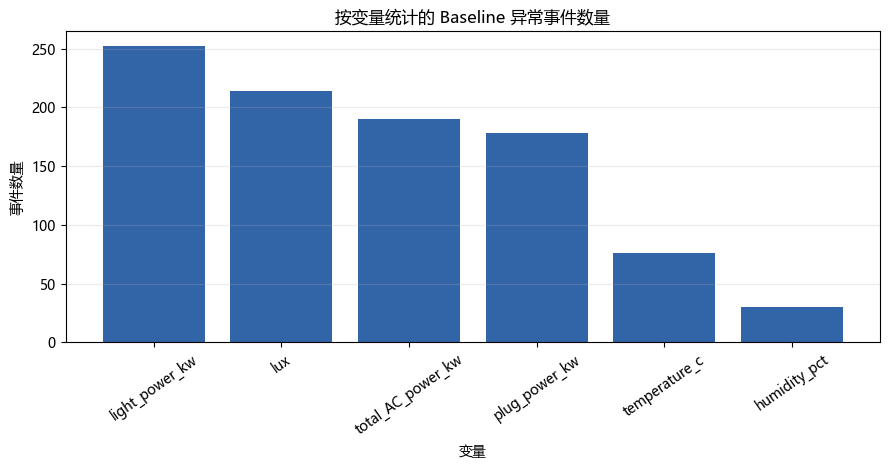

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline\baseline_figures\02_anomaly_events_by_zone.png


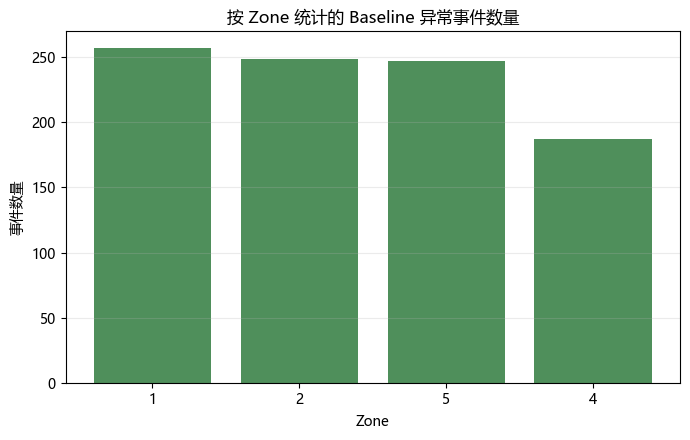

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline\baseline_figures\03_anomaly_points_by_operating_period.png


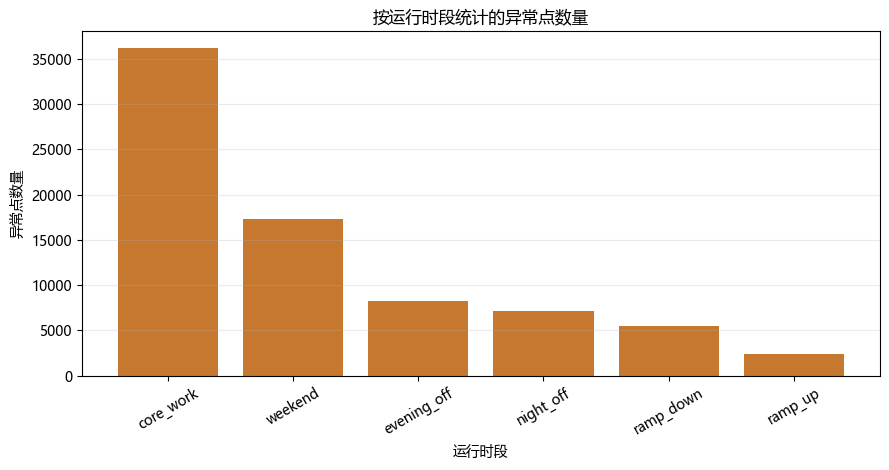

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline\baseline_figures\04_anomaly_heatmap_variable_hour.png


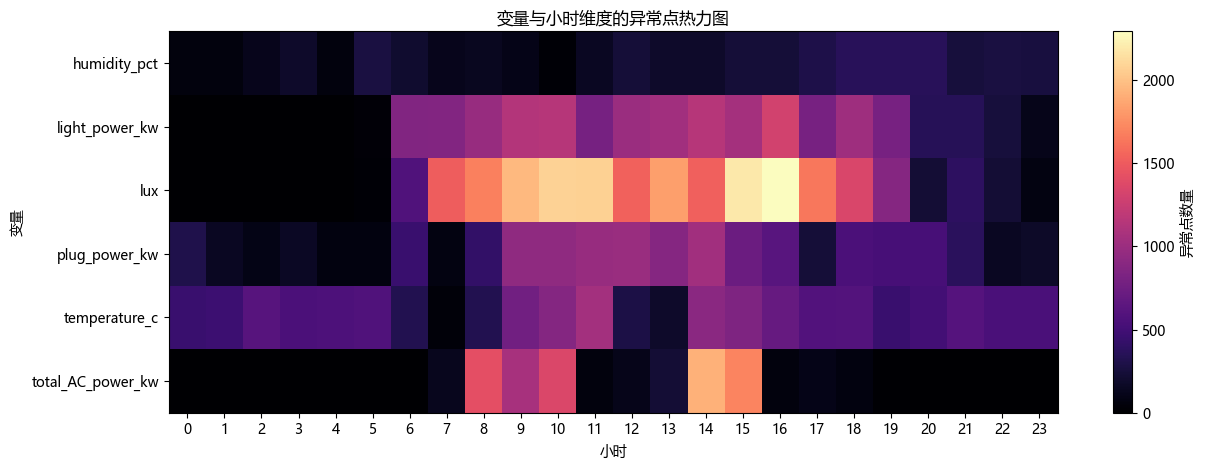

In [12]:

def save_current_figure(file_name: str) -> None:
    path = FIGURE_DIR / file_name
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    safe_print("已保存图表:", path)


def plot_count_heatmap(table: pd.DataFrame, title: str, x_label: str, y_label: str, file_name: str) -> None:
    if table.empty:
        return

    fig_width = max(8, 1.25 * len(table.columns) + 3)
    fig_height = max(4.5, 0.55 * len(table.index) + 2.4)
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    im = ax.imshow(table.values, aspect="auto", cmap="YlOrRd")
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(table.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index)
    fig.colorbar(im, ax=ax, label="异常点数量")

    max_value = table.values.max() if table.size else 0
    text_color_threshold = max_value * 0.55
    for row_index in range(table.shape[0]):
        for col_index in range(table.shape[1]):
            value = int(table.iat[row_index, col_index])
            color = "white" if value > text_color_threshold else "black"
            ax.text(col_index, row_index, value, ha="center", va="center", color=color, fontsize=9)

    save_current_figure(file_name)
    plt.show()


if not summary_by_variable.empty:
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.bar(summary_by_variable["variable"], summary_by_variable["events"], color="#3264a8")
    ax.set_title("按变量统计的 Baseline 异常事件数量")
    ax.set_xlabel("变量")
    ax.set_ylabel("事件数量")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("01_anomaly_events_by_variable.png")
    plt.show()

if not summary_by_zone.empty:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.bar(summary_by_zone["zone"].astype(str), summary_by_zone["events"], color="#4f8f5b")
    ax.set_title("按 Zone 统计的 Baseline 异常事件数量")
    ax.set_xlabel("Zone")
    ax.set_ylabel("事件数量")
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("02_anomaly_events_by_zone.png")
    plt.show()

if not summary_by_period.empty:
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.bar(summary_by_period["operating_period"], summary_by_period["anomaly_points"], color="#c6782f")
    ax.set_title("按运行时段统计的异常点数量")
    ax.set_xlabel("运行时段")
    ax.set_ylabel("异常点数量")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("03_anomaly_points_by_operating_period.png")
    plt.show()

if not anomaly_points.empty:
    heatmap = anomaly_points.groupby(["variable", "hour"]).size().unstack("hour", fill_value=0)
    fig, ax = plt.subplots(figsize=(13, 4.8))
    im = ax.imshow(heatmap.values, aspect="auto", cmap="magma")
    ax.set_title("变量与小时维度的异常点热力图")
    ax.set_xlabel("小时")
    ax.set_ylabel("变量")
    ax.set_xticks(range(len(heatmap.columns)))
    ax.set_xticklabels(heatmap.columns)
    ax.set_yticks(range(len(heatmap.index)))
    ax.set_yticklabels(heatmap.index)
    fig.colorbar(im, ax=ax, label="异常点数量")
    save_current_figure("04_anomaly_heatmap_variable_hour.png")
    plt.show()

plot_count_heatmap(
    summary_variable_period,
    "变量与运行时段维度的异常点热力图",
    "运行时段",
    "变量",
    "05_anomaly_heatmap_variable_operating_period.png",
)

plot_count_heatmap(
    summary_zone_period,
    "Zone 与运行时段维度的异常点热力图",
    "运行时段",
    "Zone",
    "06_anomaly_heatmap_zone_operating_period.png",
)



### 本步骤结果解释

这个 cell 生成 baseline 结果的总体可视化，包括按变量、按 zone、按运行时段、按 15 分钟时间槽分布，以及新增的两个运行时段交叉热力图。

新增的 `变量 × 运行时段` 热力图用于判断异常是否集中在某些字段和某些建筑运行阶段。例如，如果 `light_power_kw` 或 `lux` 在 `evening_off`、`night_off` 或 `weekend` 中异常较多，可能说明非工作时间存在照明或占用相关异常；如果 `total_AC_power_kw` 在 `core_work` 或 `ramp_down` 中异常较多，则可能与空调运行策略、关闭延迟或负载波动有关。

新增的 `Zone × 运行时段` 热力图用于判断异常是否集中在某些空间区域和某些时间阶段。这样比只看每个 zone 的总异常数量更清楚，因为同样的总数可能来自完全不同的运行背景：一个 zone 可能主要在工作时间异常，另一个 zone 可能主要在周末或夜间异常。

使用 heatmap 的原因是它能同时展示两个维度的分布，比单独的柱状图更适合比较“变量/区域”和“时间段”之间的关系。这些图可以帮助后续选择代表性异常事件，并为机器学习模型结果提供可解释的对照。


## 13. 代表性异常事件图

本步骤绘制排名最高的异常事件。每张图展示事件窗口前后实际 15 分钟 rolling 值与情境 baseline median 的对比，并用红色点标出最终异常点。


已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline\baseline_figures\event_001_zone4_light_power_kw.png


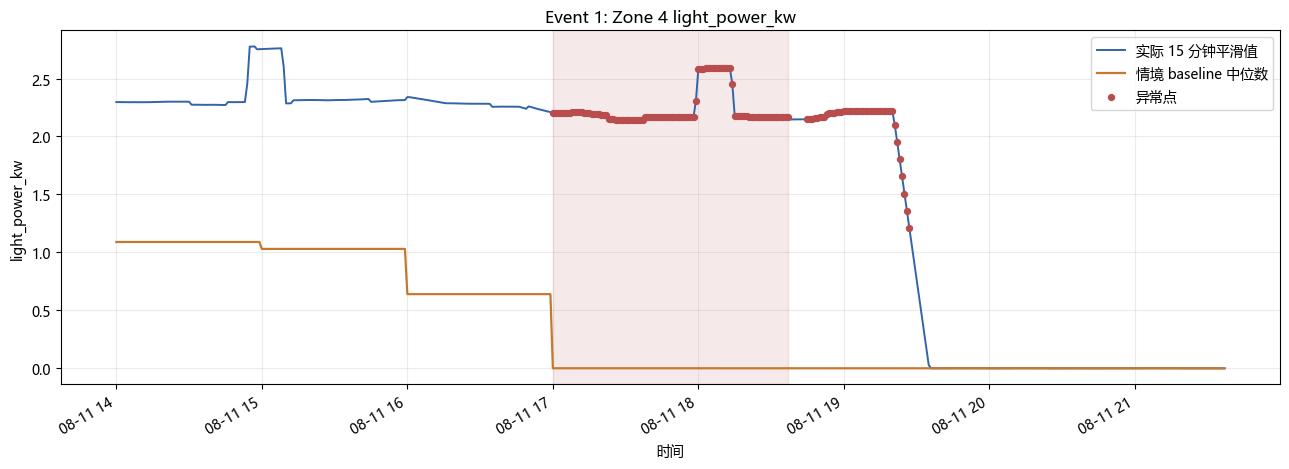

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline\baseline_figures\event_002_zone4_light_power_kw.png


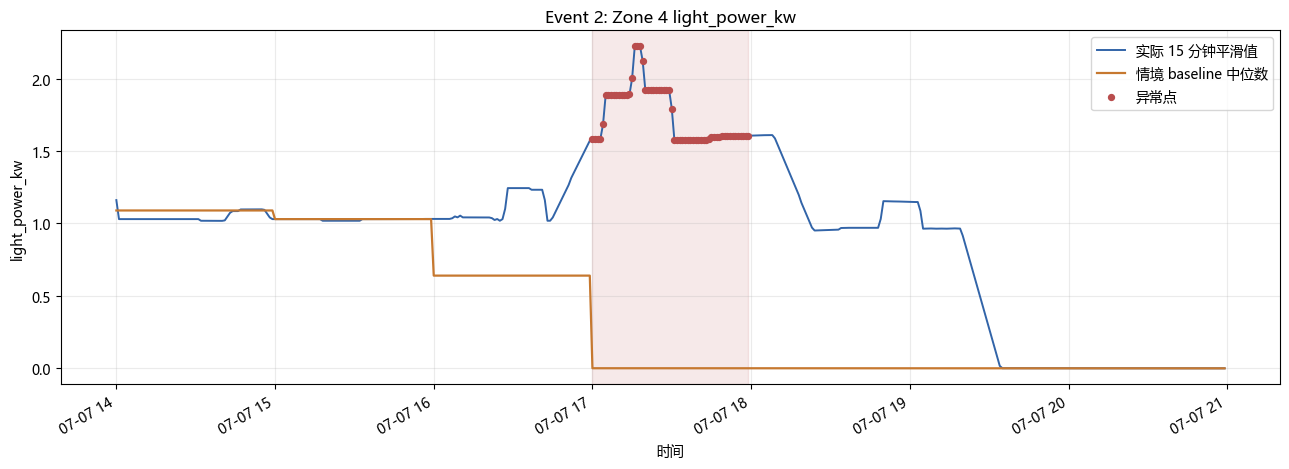

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline\baseline_figures\event_003_zone4_light_power_kw.png


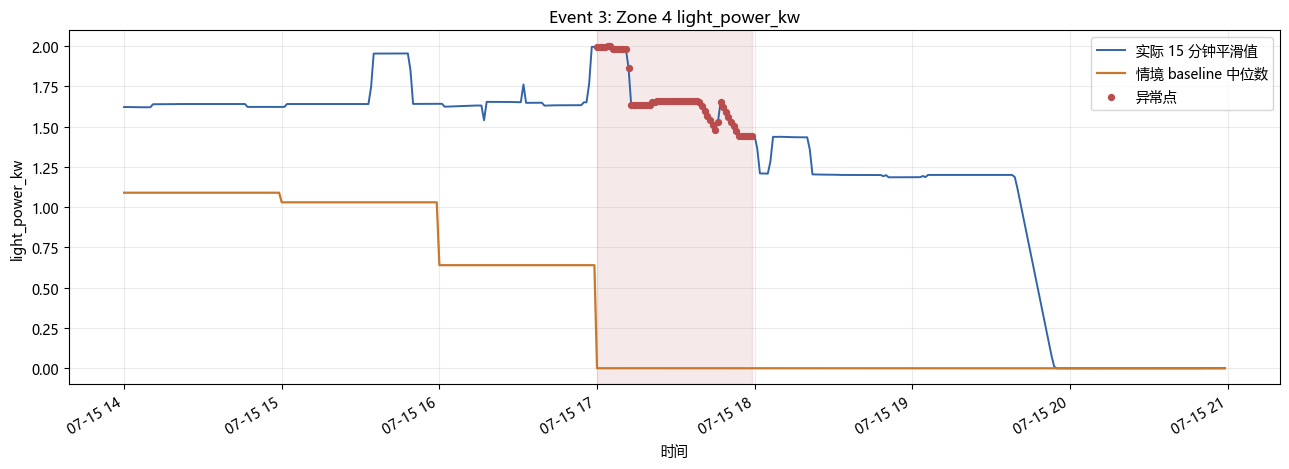

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline\baseline_figures\event_004_zone4_light_power_kw.png


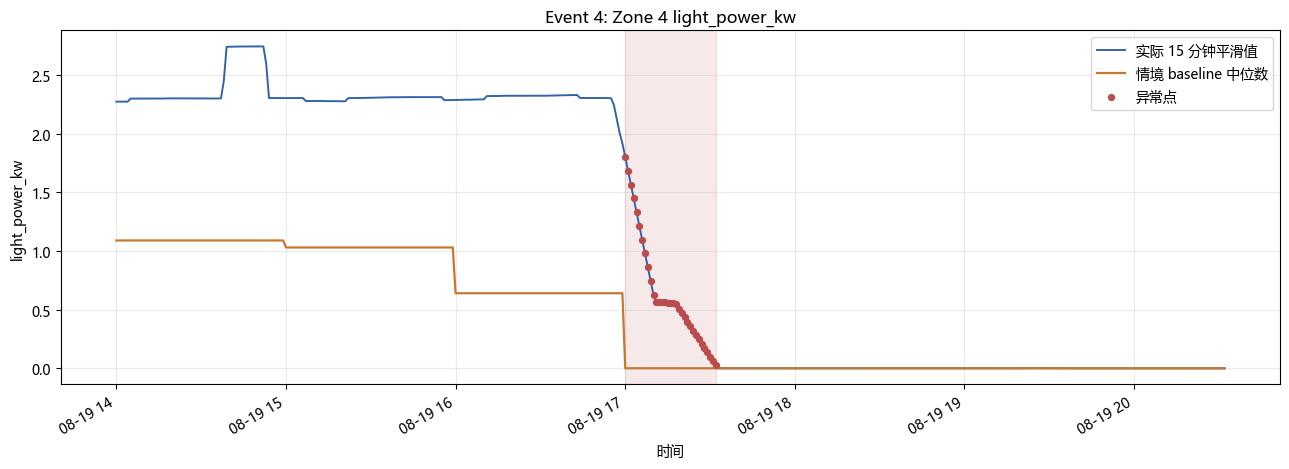

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline\baseline_figures\event_005_zone4_light_power_kw.png


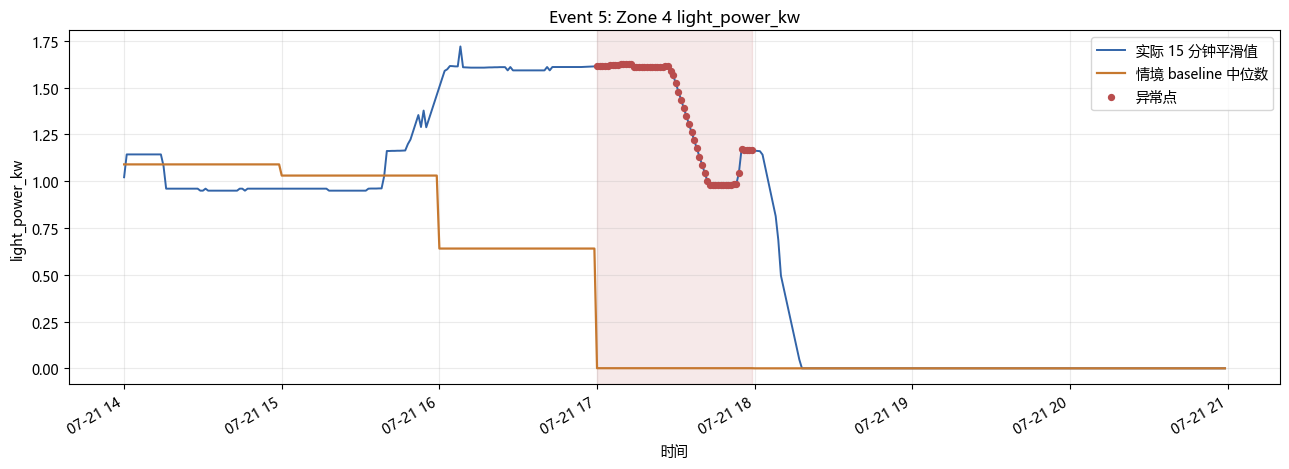

In [13]:
def plot_event(event_row: pd.Series, window_minutes: int = 180) -> None:
    start = pd.to_datetime(event_row["start_time"]) - pd.Timedelta(minutes=window_minutes)
    end = pd.to_datetime(event_row["end_time"]) + pd.Timedelta(minutes=window_minutes)
    subset = scores[
        (scores["zone"] == event_row["zone"])
        & (scores["variable"] == event_row["variable"])
        & (scores["timestamp"].between(start, end))
    ].copy()

    fig, ax = plt.subplots(figsize=(13, 4.8))
    ax.plot(subset["timestamp"], subset["actual_value"], label="实际 15 分钟平滑值", color="#3264a8", linewidth=1.4)
    ax.plot(subset["timestamp"], subset["baseline_median"], label="情境 baseline 中位数", color="#c6782f", linewidth=1.6)
    event_mask = subset["is_anomaly"]
    ax.scatter(subset.loc[event_mask, "timestamp"], subset.loc[event_mask, "actual_value"], color="#b94d4d", s=18, label="异常点", zorder=3)
    ax.axvspan(pd.to_datetime(event_row["start_time"]), pd.to_datetime(event_row["end_time"]), color="#b94d4d", alpha=0.12)
    ax.set_title(f"Event {int(event_row['event_id'])}: Zone {event_row['zone']} {event_row['variable']}")
    ax.set_xlabel("时间")
    ax.set_ylabel(event_row["variable"])
    ax.legend()
    ax.grid(True, alpha=0.25)
    fig.autofmt_xdate()
    save_current_figure(f"event_{int(event_row['event_id']):03d}_zone{event_row['zone']}_{event_row['variable']}.png")
    plt.show()


top_events = anomaly_events.head(5).copy()
for _, event in top_events.iterrows():
    plot_event(event)


### 本步骤结果解释

这个 cell 绘制排名最高的 5 个 anomaly events。每张图会显示事件前后窗口中实际 15 分钟平滑值和对应的 contextual baseline median，并用红色点标出最终异常点。

这样做的原因是单纯的分数表不够直观。通过事件图，可以检查异常是否真的明显偏离 baseline，也可以观察异常是突然尖峰、持续升高、持续偏低，还是与某个运行时段转换有关。

这些代表性图适合放入报告中，用来解释 baseline 方法如何发现并呈现异常候选。


## 14. 最终验证

最终验证用于确认所有预期 baseline 输出均已生成，并记录本次统计 baseline 的关键建模设置。


In [14]:
final_validation = pd.DataFrame([{
    "input_dataset": INPUT_DATASET.name,
    "rows_input_wide": len(df),
    "rows_input_long": len(baseline_long),
    "baseline_profile_rows": len(baseline_profile),
    "anomaly_score_rows": len(scores),
    "anomaly_points": int(scores["is_anomaly"].sum()),
    "anomaly_events": len(anomaly_events),
    "robust_z_threshold": ROBUST_Z_THRESHOLD,
    "min_persistence_minutes": MIN_PERSISTENCE_MINUTES,
    "baseline_grouping": " + ".join(BASELINE_GROUP_COLUMNS),
    "operating_periods": ",".join(sorted(df["operating_period"].unique())),
    "table_count": len(list(TABLE_DIR.glob("*.csv"))) + len(list(TABLE_DIR.glob("*.csv.gz"))),
    "figure_count": len(list(FIGURE_DIR.glob("*.png"))),
}])
final_validation.to_csv(TABLE_DIR / "17_final_validation_summary.csv", index=False)

display(final_validation)
safe_print("Baseline 输出目录:", OUTPUT_DIR)
safe_print("Baseline 表格目录:", TABLE_DIR)
safe_print("Baseline 图表目录:", FIGURE_DIR)


,input_dataset,rows_input_wide,rows_input_long,baseline_profile_rows,anomaly_score_rows,anomaly_points,anomaly_events,robust_z_threshold,min_persistence_minutes,baseline_grouping,operating_periods,table_count,figure_count
0,floor6_zone1245_baseline_ready_2018_jul01_sep0...,362864,2177184,1152,2177184,76773,940,3.5,15,zone + day_type + hour + variable,"core_work,evening_off,night_off,ramp_down,ramp...",17,9


Baseline 输出目录: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline
Baseline 表格目录: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline\baseline_tables
Baseline 图表目录: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline\baseline_figures


### 本步骤结果解释

最终验证表确认本 notebook 已完整生成 v2a baseline 输出：wide 输入 362,864 行，long scoring 表 2,177,184 行，baseline profile 4,608 行，最终异常点 84,116 个，合并后 anomaly events 为 1,248 个。

同时，验证表记录了关键方法设置：baseline 分组为 `zone + day_type + 15min_slot + variable`，robust z-score 阈值为 3.5，最小持续时间为 15 分钟，运行时段包含 6 类。

这个版本的作用是测试时间粒度敏感性。与 v1 相比，v2a 更精细但也更敏感，因此后续报告中应重点比较 v1 和 v2a 是否发现相同的主要异常模式，而不是只比较异常数量多少。
